<a href="https://colab.research.google.com/github/Riot808s/FUNDAI-Laboratories-Balona/blob/main/Lab8_Supervised_Learning_Balona.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 8: Supervised Learning Algorithms

## Fundamentals of Artificial Intelligence

**Name:** Kylle Ian A. Balona

**Course:** BSCSAI

**Section:** 2A

**Date:** 11/4/2026

**Dataset Sources:**
1. California Housing: 'sklearn.datasets.fetch_california_housing
2. Breast Cancer: 'sklearn.datasets.load_breast_cancer

**GitHub URL:** https://github.com/Riot808s/FUNDAI-Laboratories-Balona



In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Models
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier

# Tools & Metrics
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, confusion_matrix, classification_report, roc_curve, auc

# Datasets
from sklearn.datasets import fetch_california_housing, load_breast_cancer

import warnings
warnings.filterwarnings('ignore')

In [72]:
# Load dataset
housing = fetch_california_housing()
X_housing = pd.DataFrame(housing.data, columns = housing.feature_names)
y_housing = housing.target

# Split data
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_housing, y_housing, test_size = 0.2, random_state = 42
)

print(f"Training set size: {X_train_reg.shape}")
print(f"Testing set size: {X_test_reg.shape}")

Training set size: (16512, 8)
Testing set size: (4128, 8)


In [73]:
# Initiate and train
lin_reg = LinearRegression()
lin_reg.fit(X_train_reg, y_train_reg)

# Predict
y_pred_reg = lin_reg.predict(X_test_reg)

# Evaluate
mse = mean_squared_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_reg, y_pred_reg)

print("Linear Regression Metrics")
print("=" * 30)
print(f"RMSE: {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")

Linear Regression Metrics
RMSE: 0.7456
R2 Score: 0.5758


### Interpreting the Weights


In [74]:
coefficients = pd.DataFrame({
    'Feature': X_housing.columns,
    'Coefficient (Weight)': lin_reg.coef_
}).sort_values(by = 'Coefficient (Weight)', key = abs, ascending = False)

print(coefficients)

      Feature  Coefficient (Weight)
3   AveBedrms              0.783145
0      MedInc              0.448675
7   Longitude             -0.433708
6    Latitude             -0.419792
2    AveRooms             -0.123323
1    HouseAge              0.009724
5    AveOccup             -0.003526
4  Population             -0.000002


In [75]:
# Load dataset
cancer = load_breast_cancer()
X_cancer = pd.DataFrame(cancer.data, columns = cancer.feature_names)
y_cancer = cancer.target

# Split data
X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(
    X_cancer, y_cancer, test_size = 0.3, stratify = y_cancer, random_state = 42
)

In [76]:
log_reg_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter = 10000, random_state = 42))
])

log_reg_pipeline.fit(X_train_log, y_train_log)
y_pred_log = log_reg_pipeline.predict(X_test_log)

print("LOGISTIC REGRESSION METRICS")
print("=" * 30)
print(f"Accuracy: {accuracy_score(y_test_log, y_pred_log):.4f}")
print("\nClassification Report:")
print(classification_report(y_test_log, y_pred_log, target_names = cancer.target_names))

LOGISTIC REGRESSION METRICS
Accuracy: 0.9883

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        64
      benign       0.99      0.99      0.99       107

    accuracy                           0.99       171
   macro avg       0.99      0.99      0.99       171
weighted avg       0.99      0.99      0.99       171



Confusion Matrix:
[[ 63   1]
 [  1 106]]


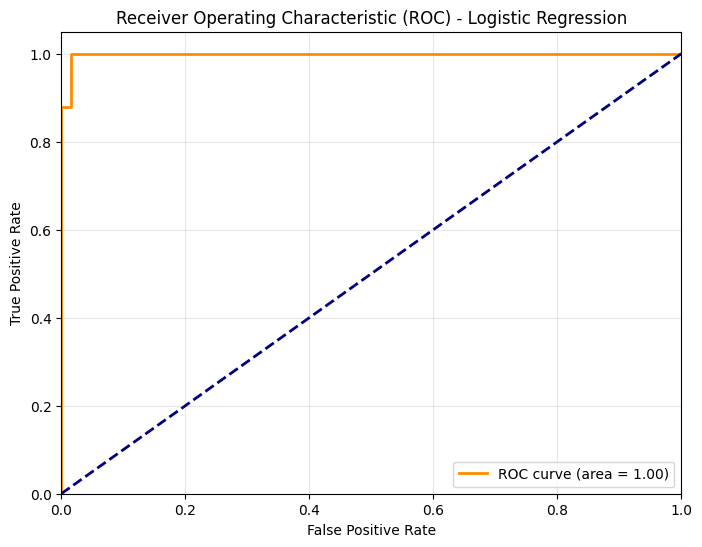

In [77]:
# Confusion Matrix
cm = confusion_matrix(y_test_log, y_pred_log)
print("Confusion Matrix:")
print(cm)

# ROC Curve
# Get probability scores for the positive class (Benign)
y_probs = log_reg_pipeline.predict_proba(X_test_log)[:, 1]
fpr, tpr, _ = roc_curve(y_test_log, y_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize = (8, 6))
plt.plot(fpr, tpr, color = 'darkorange', lw = 2, label = f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color = 'navy', lw = 2, linestyle = '--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) - Logistic Regression')
plt.legend(loc = "lower right")
plt.grid(alpha = 0.3)
plt.show()